# Article figures

Run from top to bottom with the **R** kernel.
All plotting code is contained in this notebook; inputs are saved CSV files in `article/evidence/`.
Each figure cell displays one plot and exports PDF and PNG files to `article/figures/`.
No training or evidence regeneration is performed.
The final architecture cell reproduces the historical R schematic; editable draw.io artwork is maintained separately.


## Preparation

In [328]:
library(tidyverse)
library(patchwork)
library(grid)
library(sf)
library(tmap)
library(ggpubr)

In [6]:
# Locate article/ whether launched from the repository, article/, or scripts/.
evidence_dir <- "../evidence"
# Optional override permits verification without replacing manuscript figures.
figure_dir <- "../figures"
dir.create(figure_dir, recursive=TRUE, showWarnings=FALSE)

In [7]:
cols <- c('DLAN'='#D55E00', 'GeoAggregator'='#009E73', 'GCNNWR'='#0072B2',
          'OLS buffer'='#777777', 'GNNWR'='#CC79A7', 'GTNNWR'='#E69F00')
options(jupyter.plot_mimetypes='image/png', repr.plot.res=120)

In [452]:
theme_set(
  theme_minimal(base_size=18, base_family='Times New Roman') +
    theme(
      panel.grid.minor = element_blank(),
      plot.title = element_text(face='bold', size = 18),
      legend.position = 'bottom',
    )
)

In [101]:
case_order <- c('CO2', 'OD-Wuhan', 'WuhanHP', 'GVI')
case_labels <- c("CE", "SIC", "SHP", "GVI")
metrics <- read.csv(file.path(evidence_dir, 'reported_metrics.csv'), check.names=FALSE) %>%
  mutate(case = factor(case, levels=case_order, labels = case_labels))
test_metrics <- filter(metrics, split=='test')
report_sum <- read.csv(file.path(evidence_dir, 'reported_summary.csv'), check.names=FALSE) %>%
  mutate(case = factor(case, levels=case_order, labels = case_labels)) %>%
  filter(split=='test')
pred <- read.csv(file.path(evidence_dir, 'reported_predictions.csv'), check.names=FALSE) %>%
  mutate(case = factor(case, levels=case_order, labels = case_labels))
supplement_metrics <- read.csv(file.path(evidence_dir, 'supplement_metrics.csv'), check.names=FALSE)
st <- subset(supplement_metrics, split=='test')
stopifnot(nrow(test_metrics)==140, all(is.finite(test_metrics$rmse)), all(is.finite(test_metrics$mae)))

## Seed-level RMSE

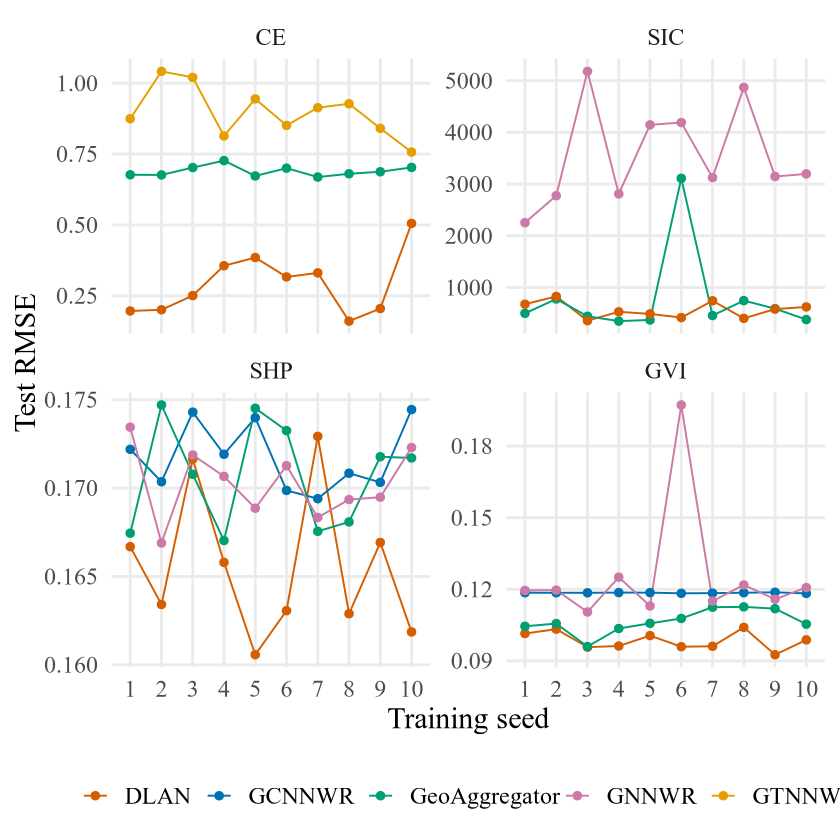

In [102]:
ggplot(test_metrics, aes(factor(seed), rmse, colour = model_label, group = model_label)) +
  geom_line(linewidth = .55) +
  geom_point(size = 1.6) +
  facet_wrap(~case, scales = "free_y", ncol = 2) +
  scale_colour_manual(values = cols) +
  labs(
    x = "Training seed",
    y = "Test RMSE",
    colour = NULL
  )


In [103]:
ggsave(file.path(figure_dir, 'matched_seed_accuracy.pdf'), width=8, height=5.3, device = cairo_pdf)


## Figure 2: RMSE and MAE boxplots

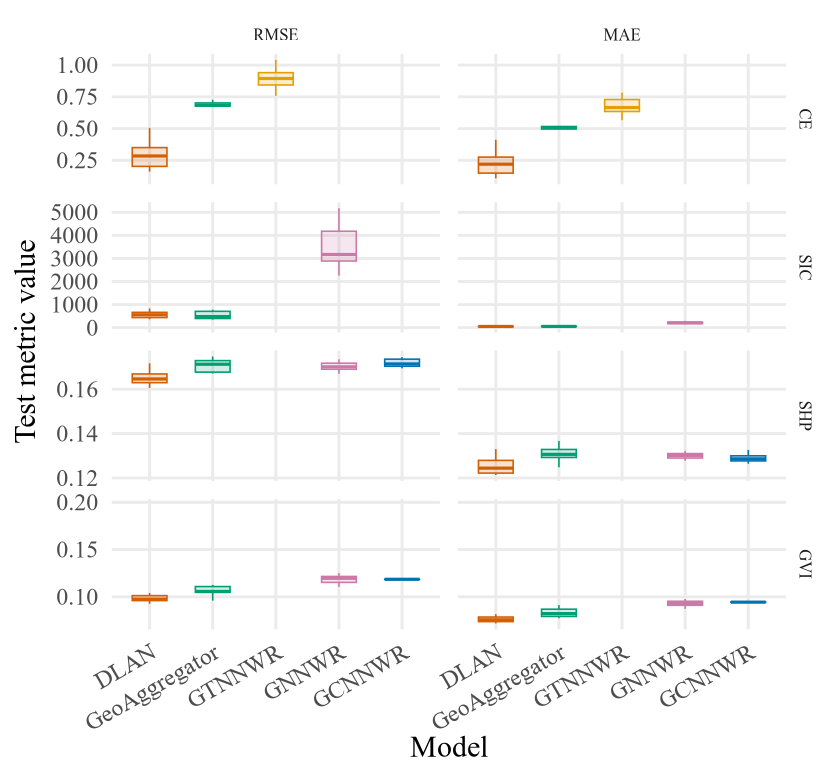

In [421]:
# Figure 2: seed-level distributions, with one dataset per row and metric per column.
accuracy_long <- rbind(
  transform(test_metrics, metric = "RMSE", value = rmse),
  transform(test_metrics, metric = "MAE", value = mae)
) %>%
  mutate(
    metric = factor(accuracy_long$metric, levels = c("RMSE", "MAE")),
    model_label = factor(
      accuracy_long$model_label,
      levels = c("DLAN", "GeoAggregator", "GTNNWR", "GNNWR", "GCNNWR")
    )
  )
ggplot(accuracy_long, aes(model_label, value, colour = model_label, fill = model_label)) +
  geom_boxplot(width = .55, alpha = .18, outlier.shape = NA, linewidth = .45) +
  facet_grid(case ~ metric, scales = "free_y") +
  scale_colour_manual(values = cols) +
  scale_fill_manual(values = cols) +
  # scale_y_continuous(expand = expansion(mult = c(.04, .09))) +
  labs(x = "Model", y = "Test metric value") +
  theme(
    legend.position = "none",
    axis.text.x = element_text(angle = 30, hjust = 1),
    strip.text = element_text(size = 10),
    panel.spacing = unit(.75, "lines")
  )

In [422]:
ggsave(file.path(figure_dir, "matched_relative_accuracy.pdf"), width = 8, height = 8.5, device = cairo_pdf)


## Accuracy and recorded fit cost

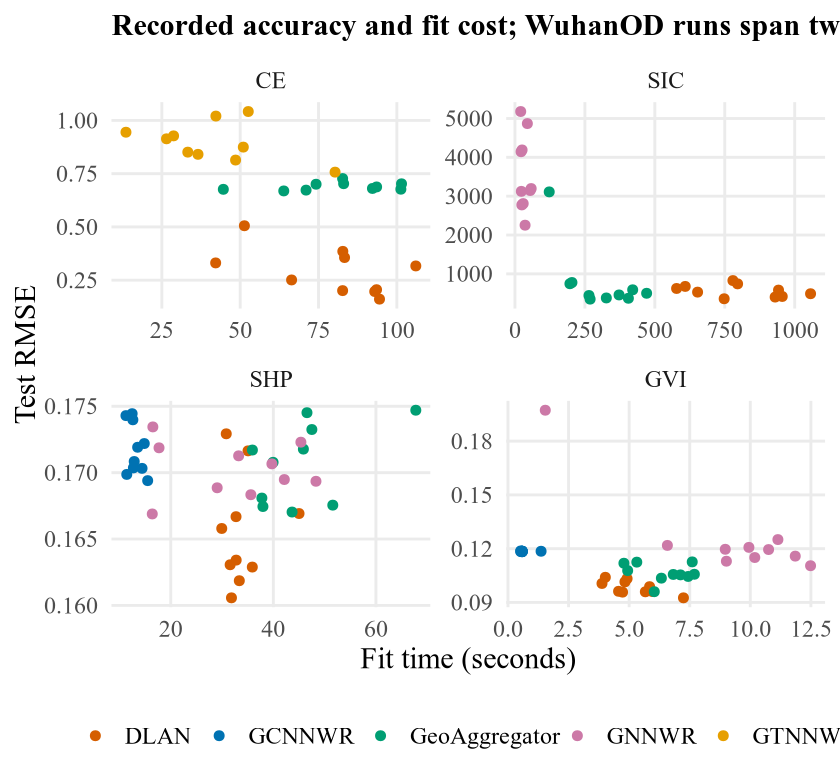

In [423]:
ggplot(test_metrics, aes(seconds, rmse, colour = model_label)) +
  geom_point(size = 2) +
  facet_wrap(~case, scales = "free", ncol = 2) +
  scale_colour_manual(values = cols) +
  labs(x = "Fit time (seconds)", y = "Test RMSE", colour = NULL, title = "Recorded accuracy and fit cost; WuhanOD runs span two machines")

In [424]:
ggsave(file.path(figure_dir, "matched_accuracy_cost.pdf"), plot = p, width = 7, height = 5.2, device = cairo_pdf)


## Coordinate-specific learned scales

In [425]:
bws <- read.csv(file.path(evidence_dir, "reported_bandwidths.csv"), check.names = FALSE) %>%
  mutate(case = factor(case, levels = case_order)) %>%
  group_by(case, axis) %>%
  summarize(
    mean_bandwidth = mean(bandwidth),
    max_bandwidth = max(bandwidth),
    min_bandwidth = min(bandwidth),
    .groups = "drop"
  ) %>%
  mutate(
    axis = axis %>%
      recode(
        "Space x" = "X",
        "Space y" = "Y",
        "Time" = "T",
        "Origin x" = "O_X",
        "Origin y" = "O_Y",
        "Destination x" = "D_X",
        "Destination y" = "D_Y"
      )
  ) %>%
  mutate(
    axis = factor(axis, levels = c("X", "Y", "T", "O_X", "O_Y", "D_X", "D_Y")),
    case = factor(case, levels = case_order, labels = case_labels)
  )
bws
bws_labeller <- \(x) (c(
  "X" = expression(italic(x)),
  "Y" = expression(italic(y)),
  "T" = expression(italic(t)),
  "O_X" = expression(italic(O)[x]),
  "O_Y" = expression(italic(O)[y]),
  "D_X" = expression(italic(D)[x]),
  "D_Y" = expression(italic(D)[y])
)[x])

case,axis,mean_bandwidth,max_bandwidth,min_bandwidth
<fct>,<fct>,<dbl>,<dbl>,<dbl>
CE,X,0.06834055,0.07381806,0.06504039
CE,Y,0.07927028,0.09111255,0.07277367
CE,T,0.18603985,0.19463322,0.16952510
SIC,D_X,0.12124172,0.12678227,0.11515542
SIC,D_Y,0.11991098,0.12762937,0.10943069
SIC,O_X,0.12595746,0.13764800,0.12028430
SIC,O_Y,0.13526528,0.14358616,0.13001052
SHP,X,0.08591601,0.09230728,0.07720852
SHP,Y,0.08614500,0.09219767,0.07816881


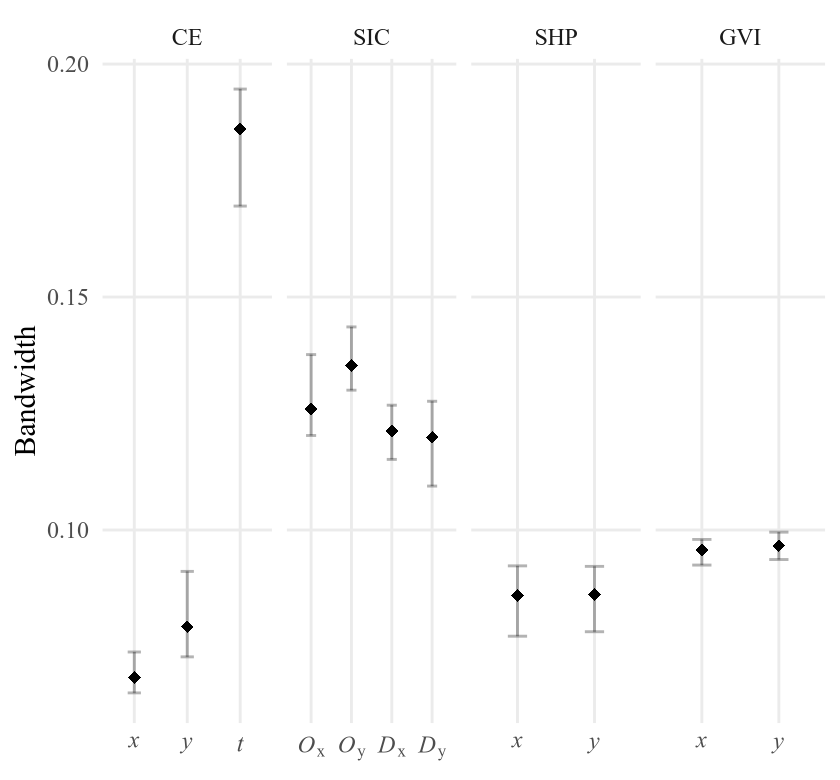

In [426]:
ggplot(bws, aes(axis, mean_bandwidth)) +
  geom_errorbar(aes(ymin = min_bandwidth, ymax = max_bandwidth), width = .25, alpha = .3) +
  stat_summary(aes(group = 1), fun = mean, geom = "point", shape = 18, size = 3, colour = "black") +
  facet_wrap(~case, scales = "free_x", nrow = 1) +
  scale_x_discrete(labels = bws_labeller) +
  labs(
    x = NULL, y = "Bandwidth"
  )

In [427]:
ggsave(file.path(figure_dir, "matched_bandwidths.pdf"), width = 7, height = 4, device = cairo_pdf)


## CO2 predictions and residuals

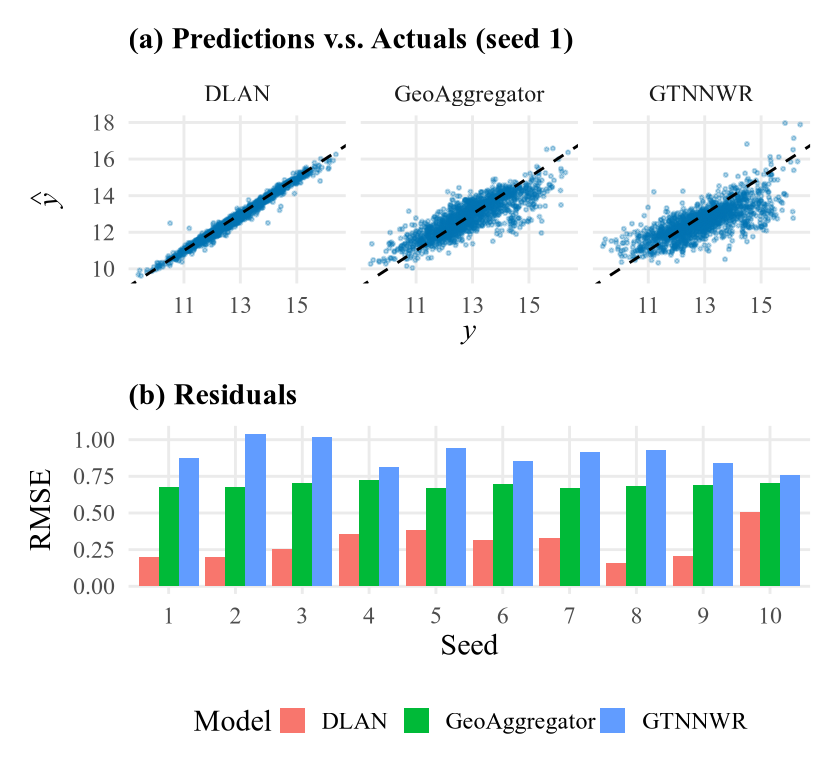

In [453]:
# Identifier-fixed example, not selected by prediction quality.
p1 <- pred %>%
  filter(case == "CE", seed == 1) %>%
  ggplot(aes(actual, predicted)) +
    geom_point(size = .6, alpha = .3, colour = "#0072B2") +
    geom_abline(slope = 1, intercept = 0, linetype = 2) +
    facet_wrap(~model, nrow = 1) +
    labs(x = expression(italic(y)), y = expression(hat(italic(y))), title = "(a) Predictions v.s. Actuals (seed 1)")
p2 <- pred %>%
  filter(case == "CE") %>%
  group_by(model, seed) %>%
  summarise(
    rmse = sqrt(mean(residual^2)),
    .groups = "drop"
  ) %>%
  ggplot(aes(as.factor(seed), rmse, fill = model)) +
    geom_col(position = "dodge") +
    labs(
      x = "Seed", y = "RMSE", title = "(b) Residuals",
      fill = "Model"
    )
p <- p1 / p2
p

In [456]:
ggsave(file.path(figure_dir, "matched_co2_predictions.pdf"), plot = p, width = 10, height = 8, device = cairo_pdf)


## WuhanHP community residuals

In [430]:
wh_base <- st_read("wuhan_subdis.gpkg")

Reading layer `wuhan_subdis' from data source 
  `/home/yigong/Works/SNWA/article/scripts/wuhan_subdis.gpkg' 
  using driver `GPKG'
Simple feature collection with 196 features and 22 fields
Geometry type: MULTIPOLYGON
Dimension:     XY
Bounding box:  xmin: 113.6966 ymin: 29.97183 xmax: 115.077 ymax: 31.36291
Geodetic CRS:  WGS 84


In [431]:
g <- subset(read.csv(file.path(evidence_dir, "matched_hp_groups.csv"), check.names = FALSE), split == "test")
# Each group receives equal weight here; ten-seed mean errors are mapped.
groups <- aggregate(cbind(rmse, mean_residual, n, x, y) ~ model + group, g, mean)
groups_sf <- st_as_sf(groups, coords = c("x", "y"), crs = 4547)
glimpse(groups_sf)

Rows: 312
Columns: 6
$ model         <chr> "DLAN", "GCNNWR", "GeoAggregator", "GNNWR", "DLAN", "GCN…
$ group         <int> 6, 6, 6, 6, 9, 9, 9, 9, 11, 11, 11, 11, 12, 12, 12, 12, …
$ rmse          <dbl> 0.08076722, 0.07585279, 0.07311793, 0.07027643, 0.090531…
$ mean_residual <dbl> -0.044679363, 0.029581657, 0.026484475, 0.009258534, 0.0…
$ n             <dbl> 13, 13, 13, 13, 26, 26, 26, 26, 13, 13, 13, 13, 27, 27, …
$ geometry      <POINT [m]> POINT (513813.1 3392252), POINT (513813.1 3392252)…


In [432]:
whhp_colors = viridisLite::viridis(5)

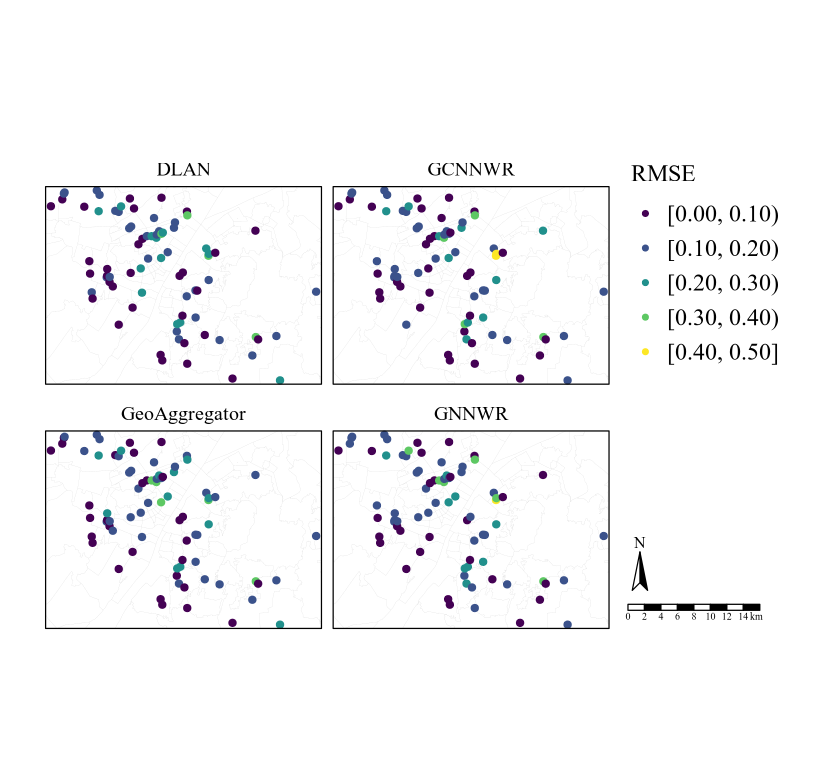

In [433]:
p1 <- tm_shape(wh_base) +
  tm_fill(col = "black", fill = "white", lwd = 0.2, col_alpha = 0.1) +
  tm_shape(groups_sf, is.main = TRUE) +
  tm_dots(
    fill = "rmse",
    fill.scale = tm_scale_intervals(
      values = whhp_colors,
      label.format = tm_label_format(
        digits = 2,
        scientific = TRUE,
        format = "f",
      )
    ),
    fill.legend = tm_legend(
      title = "RMSE",
      position = tm_pos_out("right", "center", "left", "top"),
      text.size = 1.2,
      title.size = 1.2,
    ),
    size = 0.5
  ) +
  tm_facets(by = "model", nrow = 2) +
  tm_compass(type = "arrow", position = tm_pos_out("right", "center", "left", "bottom"), size = 2) +
  tm_scalebar(position = tm_pos_out("right", "center", "left", "bottom")) +
  tm_layout(
    panel.label.size = 1.2,
    panel.label.height = 1.5,
    panel.label.frame = FALSE,
    panel.label.bg = FALSE,
    legend.frame = FALSE,
    frame.r = 0,
    margin = c(0, 0, 0, 0),
    text.fontfamily = "Times New Roman",
  )
p1

In [434]:
tmap_save(p1, file.path(figure_dir, "matched_hp_groups.pdf"), width = 8, height = 5.2, device = cairo_pdf)

Map saved to /home/yigong/Works/SNWA/article/figures/matched_hp_groups.pdf

Size: 8 by 5.194444 inches



## WuhanOD response-tail diagnostics

In [435]:
glimpse(od)

Rows: 30
Columns: 21
$ case                 <fct> SIC, SIC, SIC, SIC, SIC, SIC, SIC, SIC, SIC, SIC,…
$ model                <chr> "geoaggregator", "geoaggregator", "geoaggregator"…
$ seed                 <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 1, 2, 3, 4, 5, 6, …
$ split                <chr> "test", "test", "test", "test", "test", "test", "…
$ protocol             <chr> "frozen_ordinary_OD_split", "frozen_ordinary_OD_s…
$ scoring              <chr> "original_OD_count", "original_OD_count", "origin…
$ config_digest        <chr> "1eecd31350d9a4ad67e958ccbd9b0af7c96904f4ca56182d…
$ parameters           <int> 7069, 7069, 7069, 7069, 7069, 7069, 7069, 7069, 7…
$ epochs               <int> 300, 300, 225, 258, 295, 205, 249, 255, 300, 300,…
$ seconds              <dbl> 470.72295, 203.78113, 264.66306, 268.70671, 405.4…
$ mae                  <dbl> 54.71961, 65.68322, 45.42679, 43.21130, 45.97530,…
$ rmse                 <dbl> 500.2594, 777.8718, 443.3226, 349.6637, 371.9444,…
$ r2               

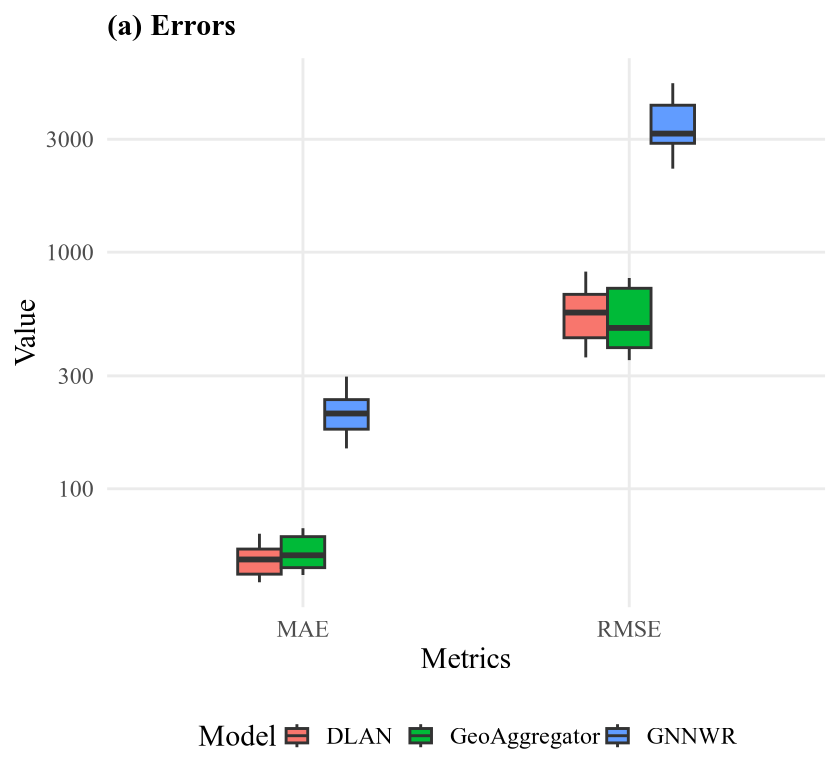

In [436]:
od <- subset(test_metrics, case == "SIC")
p1 <- od %>%
  select(model_label, mae, rmse) %>%
  pivot_longer(cols = c(mae, rmse), names_to = "metric", values_to = "value") %>%
  mutate(
    metric = recode(metric, "rmse" = "RMSE", "mae" = "MAE"),
  ) %>%
  ggplot(aes(metric, value, fill = model_label)) +
    geom_boxplot(width = .4, outlier.shape = NA, position = "dodge") +
    scale_y_log10() +
    labs(x = "Metrics", y = "Value", title = "(a) Errors", fill = "Model")
p1

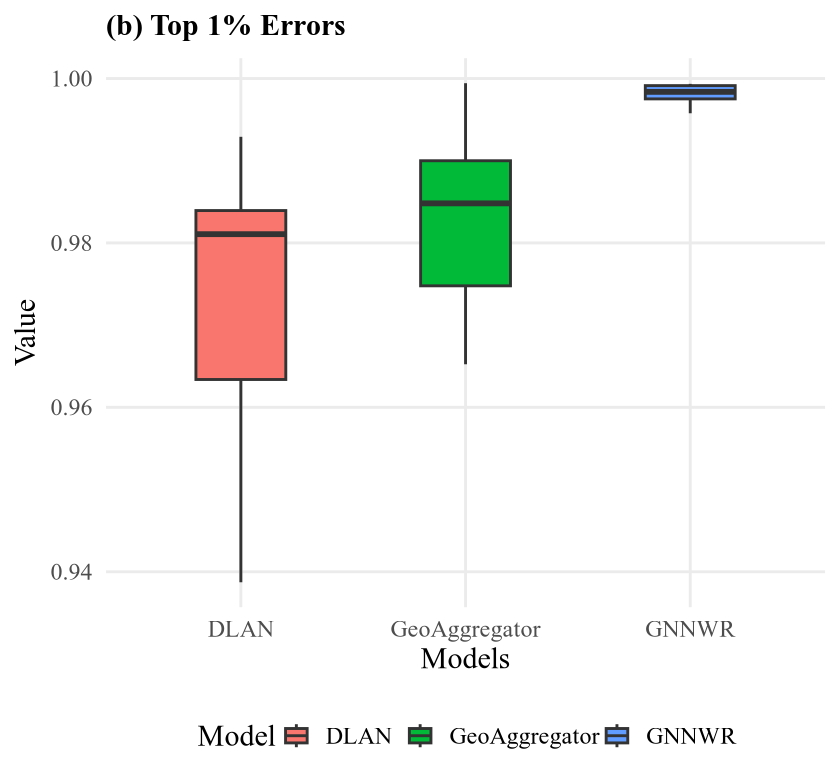

In [437]:
p2 <- od %>%
  ggplot(aes(model_label, upper_1pct_sse_share, fill = model_label)) +
    geom_boxplot(width = .4, outlier.shape = NA, position = "dodge") +
    labs(x = "Models", y = "Value", title = "(b) Top 1% Errors", fill = "Model") +
    theme(
      # legend.position = "none"
    )
p2

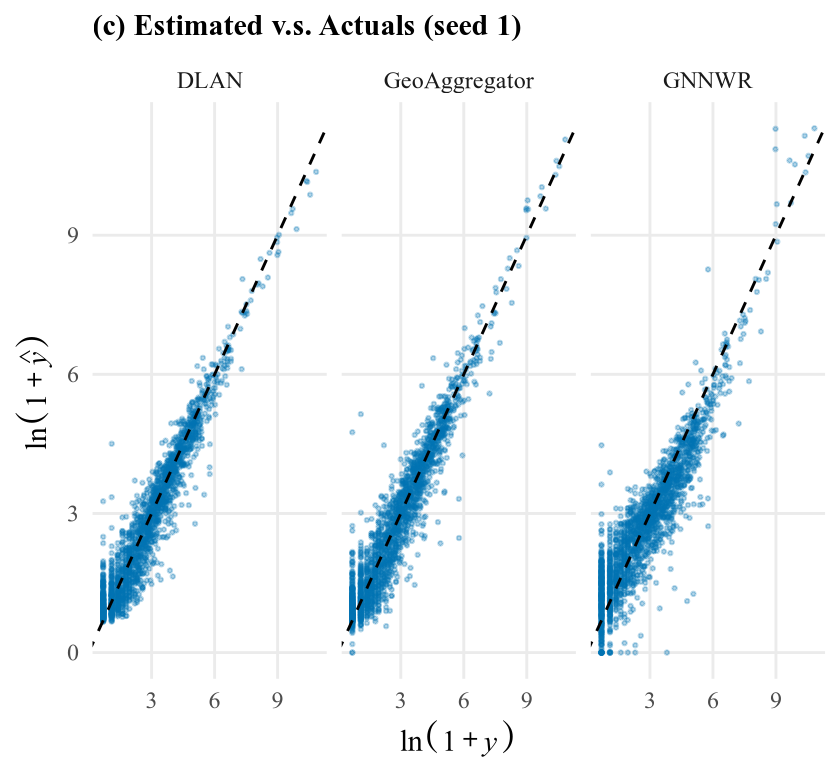

In [438]:
p3 <- ggplot(subset(pred, case == "SIC" & seed == 1), aes(log1p(actual), log1p(predicted))) +
  geom_point(size = .7, alpha = .3, colour = "#0072B2") +
  geom_abline(slope = 1, intercept = 0, linetype = 2) +
  facet_wrap(~model, nrow = 1) +
  labs(
    x = expression(ln(1+italic(y))),
    y = expression(ln(1+hat(italic(y)))),
    title = "(c) Estimated v.s. Actuals (seed 1)"
  )
p3

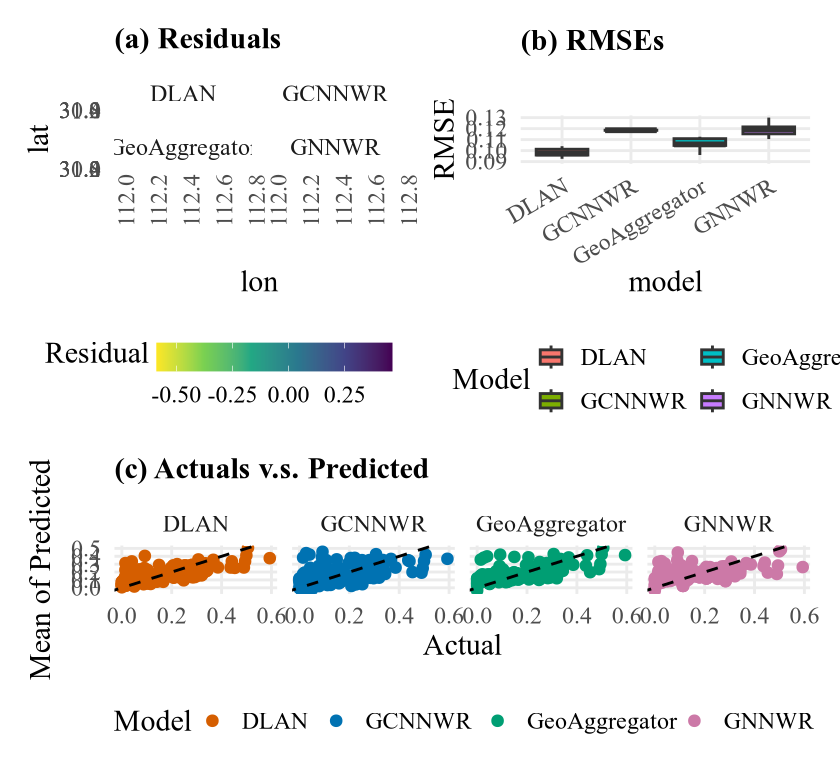

In [448]:
p <- (p1 + p2 + plot_layout(guides = "collect")) / p3
p

In [440]:
ggsave(file.path(figure_dir, "matched_od_tail.pdf"), plot = p, width = 10, height = 10, device = cairo_pdf)


## GVI prediction diagnostics

In [441]:
gv <- subset(pred, case == "GVI") %>%
  filter(model != "OLS buffer")
glimpse(gv)

Rows: 8,520
Columns: 11
$ case       <fct> GVI, GVI, GVI, GVI, GVI, GVI, GVI, GVI, GVI, GVI, GVI, GVI,…
$ model      <chr> "DLAN", "DLAN", "DLAN", "DLAN", "DLAN", "DLAN", "DLAN", "DL…
$ seed       <int> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ row_id     <int> 0, 1, 2, 20, 22, 23, 24, 35, 94, 95, 96, 109, 110, 112, 116…
$ actual     <dbl> 0.011624711, 0.017667824, 0.009298322, 0.221585646, 0.22158…
$ predicted  <dbl> 0.025164798, -0.011273146, 0.004450291, 0.268213600, 0.2756…
$ residual   <dbl> 0.013540087, -0.028940970, -0.004848030, 0.046627954, 0.054…
$ group      <dbl> 398, 398, 398, 409, 409, 409, 409, 325, 153, 170, 170, 153,…
$ x          <dbl> 365380.3, 365427.4, 365521.4, 366323.9, 366278.5, 366699.5,…
$ y          <dbl> 3456613, 3456630, 3456664, 3455309, 3455297, 3455639, 34556…
$ experiment <chr> "", "", "", "", "", "", "", "", "", "", "", "", "", "", "",…


In [442]:
gv_lonlat <- gv %>% st_as_sf(coords = c("x", "y"), crs = 4547) %>%
  st_transform(4326) %>%
  st_coordinates()
gv[, c("x", "y")] <- gv_lonlat

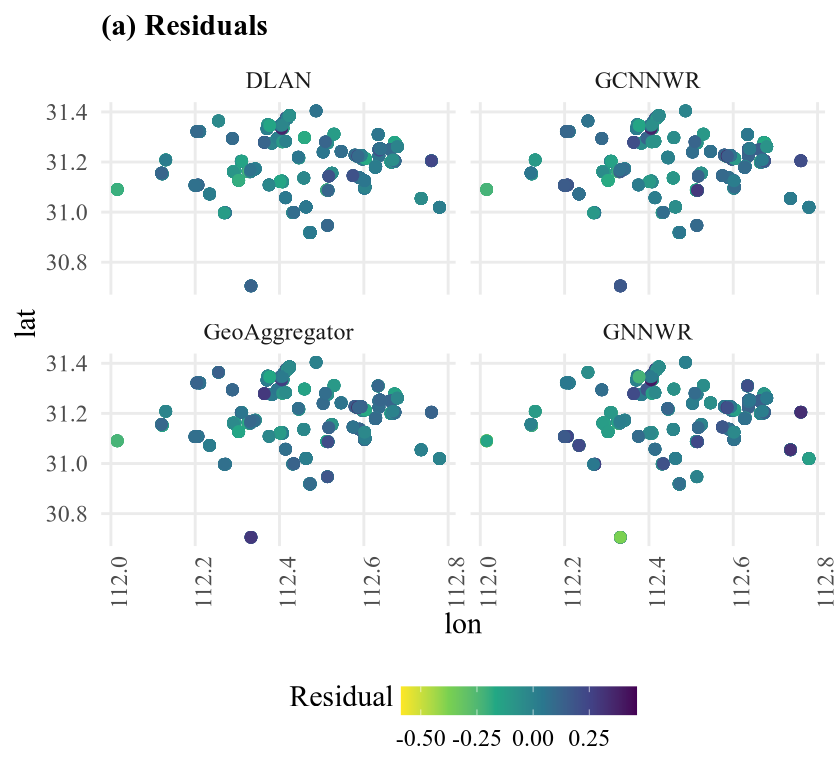

In [443]:
p1 <- ggplot(gv) +
  geom_point(aes(x, y, color = residual)) +
  scale_color_viridis_c(option = "D", direction = -1) +
  facet_wrap(~model, ncol = 2) +
  labs(
    x = "lon", y = "lat", color = "Residual",
    title = "(a) Residuals"
  ) +
  theme(
    axis.text.x = element_text(angle = 90),
    legend.position = "bottom",
    legend.key.width = unit(1, "cm"),
    legend.title = element_text(vjust = 1),
  )
p1

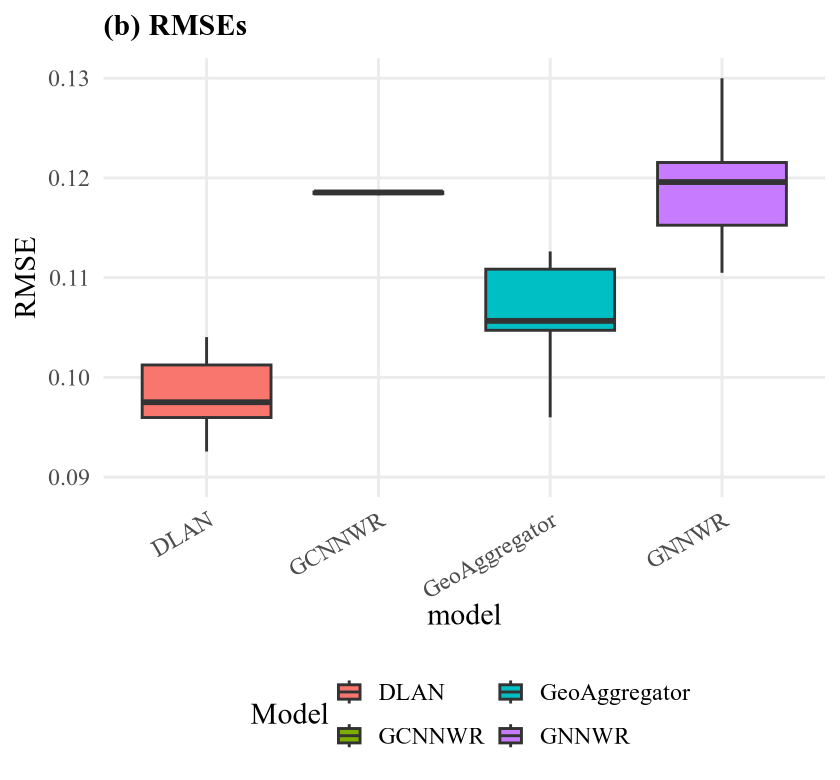

In [444]:
p2 <- gv %>%
  group_by(model, seed) %>%
  summarise(
    rmse = sqrt(mean(residual^2)),
    .groups = "drop"
  ) %>%
  ggplot(aes(model, rmse, fill = model)) +
  labs(
    x = "model", y = "RMSE", fill = "Model",
    title = "(b) RMSEs"
  ) +
  geom_boxplot() +
  scale_fill_discrete(guide = guide_legend(
    nrow = 2
  )) +
  scale_y_continuous(limits = c(0.09, 0.13), oob = scales::squish) +
  theme(
    axis.text.x = element_text(angle = 30, hjust = 1),
  )
p2

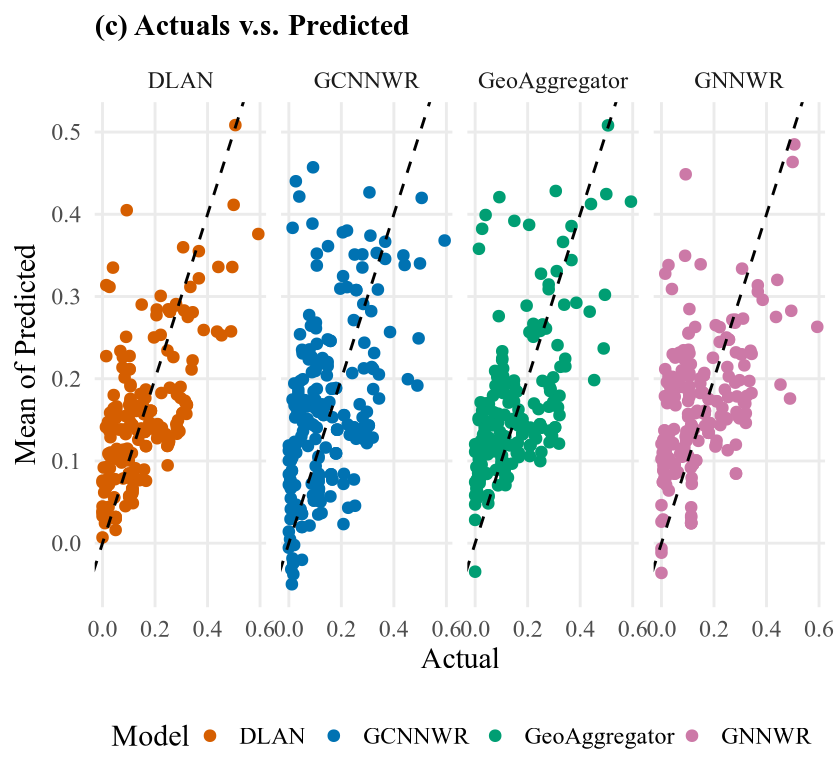

In [445]:
p3 <- gv %>%
  group_by(model, row_id) %>%
  summarise(
    actual = mean(actual),
    predicted = mean(predicted),
    .groups = "drop"
  ) %>%
  ggplot(aes(actual, predicted, colour = model, group = model)) +
  geom_point() +
  geom_abline(slope = 1, intercept = 0, linetype = 2) +
  scale_colour_manual(values = cols) +
  labs(x = "Actual", y = "Mean of Predicted", colour = "Model", title = "(c) Actuals v.s. Predicted") +
  facet_wrap(~model, nrow = 1)
p3

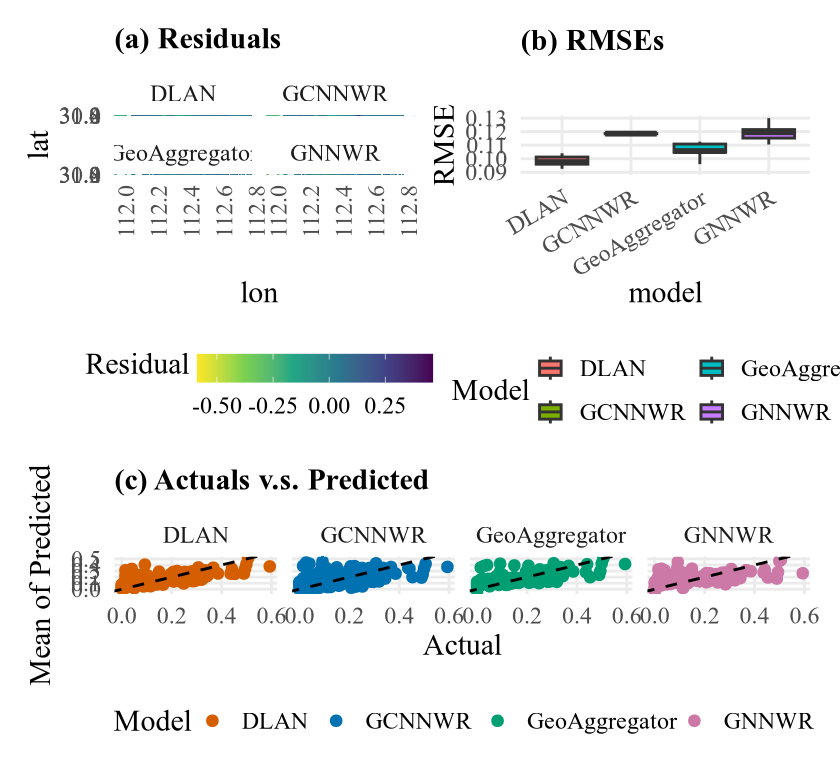

In [446]:
p <- (p1 | p2) / p3 + plot_layout(heights = c(8, 5))
p

In [447]:
ggsave(file.path(figure_dir, "matched_gvi_response.pdf"), plot = p, width = 10, height = 12, device = cairo_pdf)


## Historical Gaussian-prior ablation

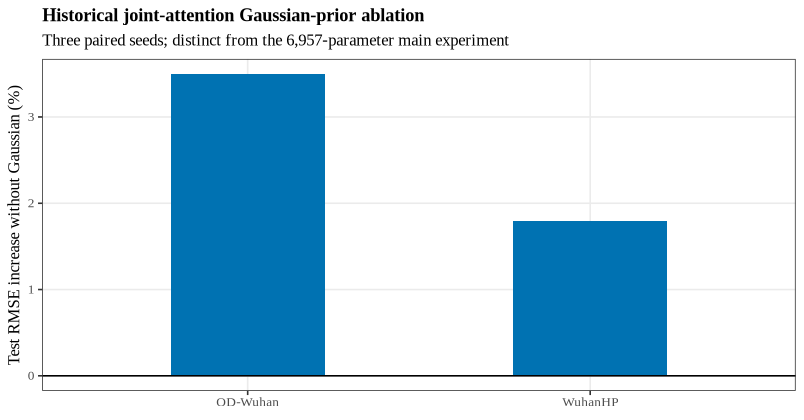

In [11]:
options(repr.plot.width=6.7, repr.plot.height=3.5)
a<-subset(read.csv(file.path(evidence_dir,'gaussian_ablation.csv'),check.names=FALSE),split=='test')
p<-ggplot(a,aes(dataset,delta_rmse_pct))+geom_col(width=.45,fill='#0072B2')+geom_hline(yintercept=0)+
 labs(x=NULL,y='Test RMSE increase without Gaussian (%)',title='Historical joint-attention Gaussian-prior ablation',subtitle='Three paired seeds; distinct from the 6,957-parameter main experiment')
ggsave(file.path(figure_dir, 'historical_gaussian_ablation.pdf'), plot=p, width=6.7, height=3.5, device=cairo_pdf)
ggsave(file.path(figure_dir, 'historical_gaussian_ablation.png'), plot=p, width=6.7, height=3.5, dpi=240)
p

## Analytical candidate-search work

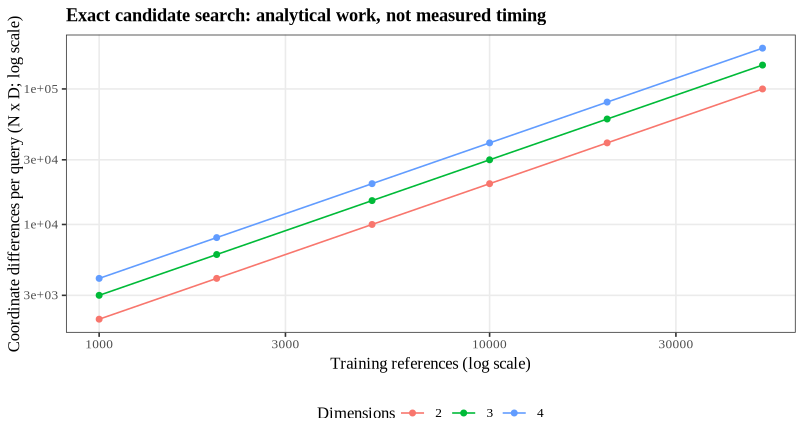

In [12]:
options(repr.plot.width=6.7, repr.plot.height=3.7)
sc<-expand.grid(N=c(1000,2000,5000,10000,20000,50000),D=c(2,3,4));sc$retrieval<-sc$N*sc$D
p<-ggplot(sc,aes(N,retrieval,colour=factor(D)))+geom_line()+geom_point()+scale_x_log10()+scale_y_log10()+
 labs(x='Training references (log scale)',y='Coordinate differences per query (N x D; log scale)',colour='Dimensions',title='Exact candidate search: analytical work, not measured timing')
ggsave(file.path(figure_dir, 'retrieval_complexity.pdf'), plot=p, width=6.7, height=3.7, device=cairo_pdf)
ggsave(file.path(figure_dir, 'retrieval_complexity.png'), plot=p, width=6.7, height=3.7, dpi=240)
p

## Historical WuhanOD capacity allocation

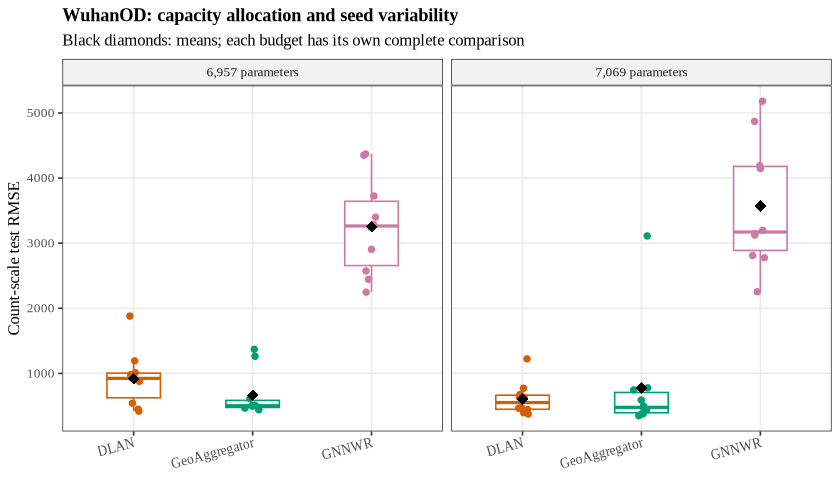

In [13]:
options(repr.plot.width=7, repr.plot.height=4)
# Supplementary protocols remain separate from the primary 6,957-parameter scores.
cap<-subset(st,experiment=='OD capacity')
base<-subset(read.csv(file.path(evidence_dir,'matched_metrics.csv'),check.names=FALSE),case=='OD-Wuhan' & split=='test');base$budget<-'6,957 parameters'
cap$budget<-'7,069 parameters'
combined<-rbind(base[,c('seed','model_label','rmse','budget')],cap[,c('seed','model_label','rmse','budget')])
p<-ggplot(combined,aes(model_label,rmse,colour=model_label))+geom_boxplot(width=.45,outlier.shape=NA)+geom_jitter(width=.07,size=1.5)+
 stat_summary(fun=mean,geom='point',shape=18,size=3,colour='black')+facet_wrap(~budget,nrow=1)+scale_colour_manual(values=cols)+
 labs(x=NULL,y='Count-scale test RMSE',colour=NULL,title='WuhanOD: capacity allocation and seed variability',subtitle='Black diamonds: means; each budget has its own complete comparison')+
 theme(axis.text.x=element_text(angle=15,hjust=1),legend.position='none')
ggsave(file.path(figure_dir, 'od_capacity_stability.pdf'), plot=p, width=7, height=4, device=cairo_pdf)
ggsave(file.path(figure_dir, 'od_capacity_stability.png'), plot=p, width=7, height=4, dpi=240)
p

## WuhanOD attention width and candidate support

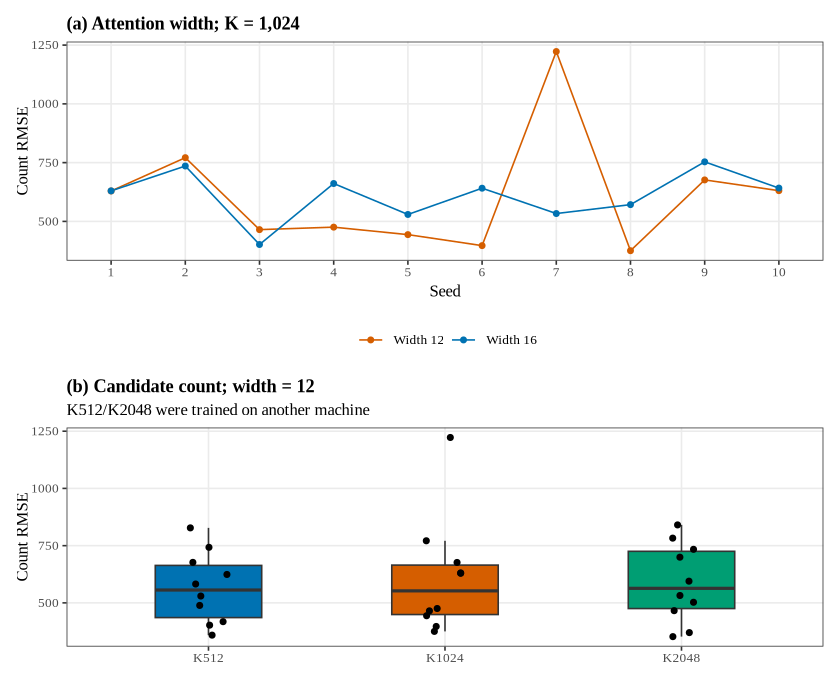

In [14]:
options(repr.plot.width=7, repr.plot.height=5.7)
w12<-subset(st,experiment=='OD capacity' & model_label=='DLAN');w12$configuration<-'Width 12'
w16<-subset(st,experiment=='OD width16');w16$configuration<-'Width 16'
w<-rbind(w12[,c('seed','rmse','configuration')],w16[,c('seed','rmse','configuration')])
p1<-ggplot(w,aes(factor(seed),rmse,colour=configuration,group=configuration))+geom_line()+geom_point()+
 scale_colour_manual(values=c('#D55E00','#0072B2'))+labs(x='Seed',y='Count RMSE',colour=NULL,title='(a) Attention width; K = 1,024')
k<-subset(st,experiment=='OD neighbours');k$configuration<-k$model_label
w12$configuration<-'K1024'
k<-rbind(k[,c('seed','rmse','configuration')],w12[,c('seed','rmse','configuration')])
k$configuration<-factor(k$configuration,levels=c('K512','K1024','K2048'))
p2<-ggplot(k,aes(configuration,rmse,fill=configuration))+geom_boxplot(width=.45,outlier.shape=NA)+geom_jitter(width=.08,size=1.4)+
 scale_fill_manual(values=c('#0072B2','#D55E00','#009E73'))+labs(x=NULL,y='Count RMSE',title='(b) Candidate count; width = 12',subtitle='K512/K2048 were trained on another machine')+theme(legend.position='none')
p <- p1/p2
ggsave(file.path(figure_dir, 'od_width_neighbours.pdf'), plot=p, width=7, height=5.7, device=cairo_pdf)
ggsave(file.path(figure_dir, 'od_width_neighbours.png'), plot=p, width=7, height=5.7, dpi=240)
p

## GVI planar and month-augmented configurations

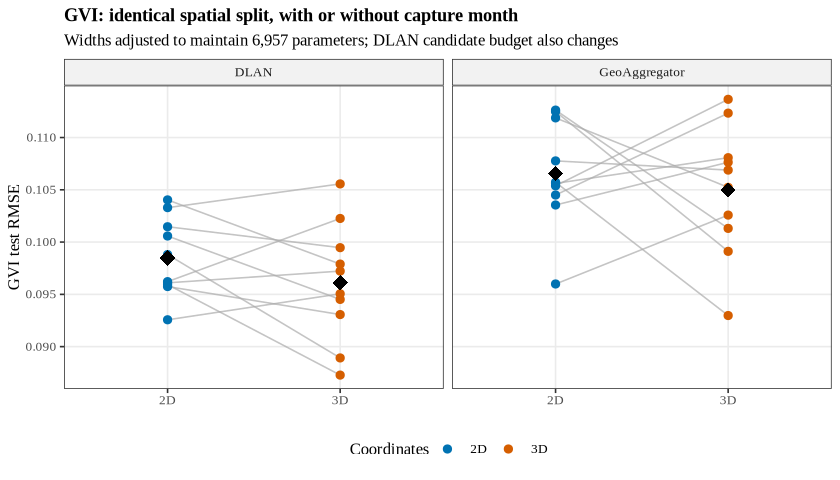

In [ ]:
options(repr.plot.width=7, repr.plot.height=4)
g3<-subset(st,experiment=='GVI 3D');g3$dimension<-'3D'
g2<-subset(test_metrics,case=='GVI' & model_label %in% c('DLAN','GeoAggregator'));g2$dimension<-'2D'
gc<-rbind(g3[,c('seed','model_label','rmse','dimension')],g2[,c('seed','model_label','rmse','dimension')])
gc$dimension<-factor(gc$dimension,levels=c('2D','3D'))
p<-ggplot(gc,aes(dimension,rmse,group=seed))+geom_line(colour='#aaaaaa',alpha=.7)+geom_point(aes(colour=dimension),size=2)+
 stat_summary(aes(group=1),fun=mean,geom='point',shape=18,size=4,colour='black')+facet_wrap(~model_label,nrow=1)+
 scale_colour_manual(values=c('#0072B2','#D55E00'))+labs(x=NULL,y='GVI test RMSE',colour='Coordinates',title='GVI: identical spatial split, with or without capture month',subtitle='Widths adjusted to maintain 6,957 parameters; DLAN candidate budget also changes')
ggsave(file.path(figure_dir, 'gvi_2d_3d.pdf'), plot=p, width=7, height=4, device=cairo_pdf)
ggsave(file.path(figure_dir, 'gvi_2d_3d.png'), plot=p, width=7, height=4, dpi=240)
p